# PLSQL-Fix: reproduce the paper's tables from the run logs

This notebook rebuilds every number in the PLSQL-Fix paper from `results/runs.csv`
(one row per agent run, exported by `agent/summarize.py`). It needs no Oracle database
and no GPU: the benchmark itself runs locally (see the repository README); this notebook
only re-checks the analysis.

* **Right fix** = tests pass **and** the agent edited the ground-truth buggy object.
* **Workaround** = tests pass, but only other objects were edited (the real bug remains).
* Paired runs = same task and seed; settings are compared with an exact McNemar test.

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest

# Kaggle dataset first, then a local clone of the repository
paths = glob.glob('/kaggle/input/**/runs.csv', recursive=True) + glob.glob('results/runs.csv') + glob.glob('runs.csv')
runs = pd.read_csv(paths[0])
print('Loaded', paths[0], '->', len(runs), 'runs,', runs.task.nunique(), 'tasks')

SETTINGS = ['none', 'dense', 'hybrid', 'graph', 'hybrid_graph']
def batch_of(task):  # 1: plain calls, 2-3: hidden dependencies (triggers, views, synonyms, types)
    n = int(task[1:4]) if task[:1] == 't' and task[1:4].isdigit() else 0
    return 3 if n >= 22 else 2 if n >= 12 else 1
runs['batch'] = runs.task.map(batch_of)
main = runs[runs.setting.isin(SETTINGS)].copy()
print(main.groupby(['category', 'setting']).size().unstack())

Loaded runs.csv -> 708 runs, 30 tasks
setting       dense  graph  hybrid  hybrid_graph  none
category                                              
cross_object     75     75      75            75    75
local            15     15      15            15    15


## Table 1: cross-object tasks (bug outside the entry object)

In [2]:
def table(df):
    g = df.groupby('setting')
    t = pd.DataFrame({
        'runs': g.size(),
        'right_fix_%': 100 * g.right_fix.mean(),
        'workaround_%': 100 * g.workaround.mean(),
        'bug_in_context_%': 100 * g.bug_in_ctx.mean(),
        'prompt_tokens': g.prompt_tok.mean(),
        'seconds': g.seconds.mean(),
    }).reindex(SETTINGS)
    return t.round(0).astype(int)

cross = main[main.category == 'cross_object']
table(cross)

,runs,right_fix_%,workaround_%,bug_in_context_%,prompt_tokens,seconds
setting,,,,,,
none,75,0,35,0,778,80
dense,75,61,9,87,1588,44
hybrid,75,64,16,88,1557,40
graph,75,73,9,92,1124,32
hybrid_graph,75,80,5,100,2110,42


### By batch (batch 1 = plain calls; batches 2 and 3 = hidden dependencies)

In [3]:
for b in (1, 2, 3):
    sub = cross[cross.batch == b]
    if sub.empty:
        continue
    print(f'Batch {b}: {sub.task.nunique()} tasks')
    display(table(sub)[['runs', 'right_fix_%', 'workaround_%', 'bug_in_context_%', 'prompt_tokens']])

Batch 1: 8 tasks


,runs,right_fix_%,workaround_%,bug_in_context_%,prompt_tokens
setting,,,,,
none,24,0,33,0,800
dense,24,67,0,96,1645
hybrid,24,75,0,88,1643
graph,24,71,0,88,1280
hybrid_graph,24,75,0,100,2198


Batch 2: 9 tasks


,runs,right_fix_%,workaround_%,bug_in_context_%,prompt_tokens
setting,,,,,
none,27,0,41,0,760
dense,27,59,22,78,1543
hybrid,27,67,22,89,1495
graph,27,67,22,100,1024
hybrid_graph,27,78,11,100,2074


Batch 3: 8 tasks


,runs,right_fix_%,workaround_%,bug_in_context_%,prompt_tokens
setting,,,,,
none,24,0,29,0,777
dense,24,58,4,88,1581
hybrid,24,50,25,88,1539
graph,24,83,4,88,1079
hybrid_graph,24,88,4,100,2063


### Local bugs (bug in the entry object)

In [4]:
table(main[main.category == 'local'])[['runs', 'right_fix_%', 'workaround_%']]

,runs,right_fix_%,workaround_%
setting,,,
none,15,87,0
dense,15,100,0
hybrid,15,100,0
graph,15,87,0
hybrid_graph,15,93,0


## Paired exact McNemar tests on right fix (cross-object, pairs = task x seed)

In [5]:
wide = cross.pivot_table(index=['task', 'seed'], columns='setting', values='right_fix', aggfunc='first').astype(bool)

def mcnemar(a, b):
    only_a = int((wide[a] & ~wide[b]).sum())
    only_b = int((~wide[a] & wide[b]).sum())
    n = only_a + only_b
    p = binomtest(only_a, n, 0.5).pvalue if n else 1.0
    return {'A': a, 'B': b, 'pairs': len(wide), 'only A right': only_a, 'only B right': only_b, 'p (exact)': round(p, 4)}

pairs = [('none', s) for s in SETTINGS[1:]] + [('dense', 'graph'), ('hybrid', 'graph'), ('graph', 'hybrid_graph'), ('hybrid', 'hybrid_graph')]
pd.DataFrame([mcnemar(a, b) for a, b in pairs])

,A,B,pairs,only A right,only B right,p (exact)
0,none,dense,75,0,46,0.0000
1,none,hybrid,75,0,48,0.0000
2,none,graph,75,0,55,0.0000
3,none,hybrid_graph,75,0,60,0.0000
4,dense,graph,75,4,13,0.0490
5,hybrid,graph,75,7,14,0.1892
6,graph,hybrid_graph,75,4,9,0.2668
7,hybrid,hybrid_graph,75,2,14,0.0042


## Figure 1: accuracy vs context size

The dependency graph reaches the accuracy of embedding and hybrid search with fewer prompt tokens.

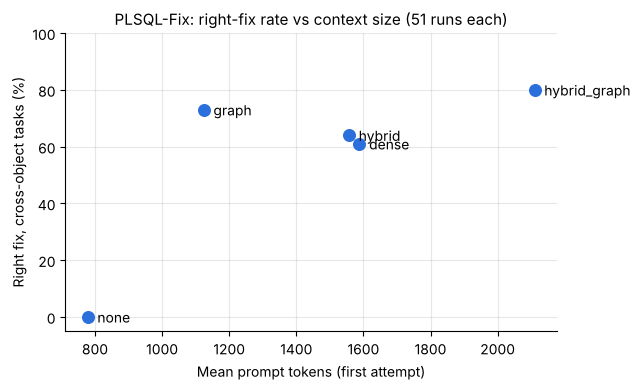

In [6]:
t = table(cross)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(t.prompt_tokens, t['right_fix_%'], s=70, color='#2a6fdb', zorder=3)
for s, r in t.iterrows():
    ax.annotate(s, (r.prompt_tokens, r['right_fix_%']), textcoords='offset points', xytext=(7, -4), fontsize=10)
ax.set_xlabel('Mean prompt tokens (first attempt)')
ax.set_ylabel('Right fix, cross-object tasks (%)')
ax.set_ylim(-5, 100)
ax.grid(alpha=0.3)
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)
ax.set_title('PLSQL-Fix: right-fix rate vs context size (51 runs each)', fontsize=11)
plt.tight_layout()
plt.savefig('figure1_accuracy_vs_tokens.png', dpi=200)
plt.show()

## Per task (right fixes out of 3 seeds)

In [7]:
per_task = cross.pivot_table(index='task', columns='setting', values='right_fix', aggfunc='sum').reindex(columns=SETTINGS).astype(int)
per_task

setting,none,dense,hybrid,graph,hybrid_graph
task,,,,,
t001_order_discount,0,2,3,1,3
t003_transfer_fee,0,1,3,3,3
t004_late_fee,0,3,3,3,3
t005_stock_reserve,0,3,3,3,2
t007_region_summary,0,3,3,3,3
t008_overpayment,0,2,2,2,3
t009_shipping_weight,0,0,0,0,0
t010_loan_payment,0,2,1,2,1
t012_scholarship_fee,0,3,3,3,3


## Table 2: larger model (Gemma 4 26B) on the hidden-dependency tasks

Batches 2 and 3, same settings and seeds; the 26B model ran on Kaggle T4 GPUs (its rows are labelled `setting@26b`).

In [8]:
b2 = runs[runs.batch.isin([2, 3]) & (runs.category == 'cross_object')].copy()
b2['size'] = b2.setting.str.contains('@26b').map({True: '26B', False: 'E4B'})
b2['base'] = b2.setting.str.replace('@26b', '', regex=False)
b2 = b2[b2.base.isin(SETTINGS)]
t2 = b2.pivot_table(index='base', columns='size', values='right_fix', aggfunc='mean').reindex(SETTINGS) * 100
big = b2[b2['size'] == '26B'].groupby('base')
t2['26B workaround'] = 100 * big.workaround.mean()
t2['26B bug in context'] = 100 * big.bug_in_ctx.mean()
t2['26B runs'] = big.size()
t2.round(0).astype(int)

size,26B,E4B,26B workaround,26B bug in context,26B runs
base,,,,,
none,2,0,35,0,51
dense,78,59,8,82,51
hybrid,88,59,12,88,51
graph,88,75,6,94,51
hybrid_graph,100,82,0,100,51


In [9]:
wide26 = b2.pivot_table(index=['task', 'seed'], columns='setting', values='right_fix', aggfunc='first').astype(bool)

def mcnemar26(a, b):
    only_a = int((wide26[a] & ~wide26[b]).sum()); only_b = int((~wide26[a] & wide26[b]).sum())
    n = only_a + only_b
    return {'A': a, 'B': b, 'pairs': len(wide26), 'only A right': only_a, 'only B right': only_b,
            'p (exact)': round(binomtest(only_a, n, 0.5).pvalue, 4) if n else 1.0}

pairs26 = [('none@26b', 'dense@26b'), ('dense@26b', 'graph@26b'), ('hybrid@26b', 'graph@26b'),
           ('graph@26b', 'hybrid_graph@26b')] + [(s, s + '@26b') for s in SETTINGS]
pd.DataFrame([mcnemar26(a, b) for a, b in pairs26])

,A,B,pairs,only A right,only B right,p (exact)
0,none@26b,dense@26b,51,0,39,0.0000
1,dense@26b,graph@26b,51,4,9,0.2668
2,hybrid@26b,graph@26b,51,6,6,1.0000
3,graph@26b,hybrid_graph@26b,51,0,6,0.0312
4,none,none@26b,51,0,1,1.0000
5,dense,dense@26b,51,0,10,0.0020
6,hybrid,hybrid@26b,51,0,15,0.0001
7,graph,graph@26b,51,0,7,0.0156
8,hybrid_graph,hybrid_graph@26b,51,0,9,0.0039


## Run conditions

Model, temperature and device of every run (most runs on CPU; a few early batch-2 runs used the laptop GPU before it became unstable).

In [10]:
runs.groupby(['model', 'temperature', 'device']).size().rename('runs').to_frame()

runs
model      temperature device           
gemma4:26b 0.2         kaggle-t4x2   255
gemma4:e4b 0.2         cpu           432
                       gpu            21